## 
1) Loading the Taxis Dataset
import seaborn as sns
# Load the 'taxis' dataset
df = sns.load_dataset("taxis")

2) Handling Missing Values
➢ Check for missing values in the dataset and identify columns with missing data.
➢ Impute missing values using appropriate strategies based on the column type (e.g.,
using mean, median, or mode for numerical columns, and mode for categorical
columns).

In [13]:
import seaborn as sns
import pandas as pd
df=sns.load_dataset("taxis")

In [16]:
df

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6428,2019-03-31 09:51:53,2019-03-31 09:55:27,1,0.75,4.5,1.06,0.0,6.36,green,credit card,East Harlem North,Central Harlem North,Manhattan,Manhattan
6429,2019-03-31 17:38:00,2019-03-31 18:34:23,1,18.74,58.0,0.00,0.0,58.80,green,credit card,Jamaica,East Concourse/Concourse Village,Queens,Bronx
6430,2019-03-23 22:55:18,2019-03-23 23:14:25,1,4.14,16.0,0.00,0.0,17.30,green,cash,Crown Heights North,Bushwick North,Brooklyn,Brooklyn
6431,2019-03-04 10:09:25,2019-03-04 10:14:29,1,1.12,6.0,0.00,0.0,6.80,green,credit card,East New York,East Flatbush/Remsen Village,Brooklyn,Brooklyn


In [43]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[us]
 1   dropoff          6433 non-null   datetime64[us]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   str           
 9   payment          6433 non-null   str           
 10  pickup_zone      6433 non-null   str           
 11  dropoff_zone     6433 non-null   str           
 12  pickup_borough   6433 non-null   str           
 13  dropoff_borough  6433 non-null   str           
dtypes: datetime64[us](2), float64(5), int64(1), str(6)


In [42]:
print("Missing values per column:\n",df.isnull().sum())

Missing values per column:
 pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


In [40]:
df['payment']=df['payment'].fillna(df['payment'].mode()[0])
df['pickup_zone']=df['pickup_zone'].fillna(df['pickup_zone'].mode()[0])
df['dropoff_zone']=df['dropoff_zone'].fillna(df['dropoff_zone'].mode()[0])
df['pickup_borough']=df['pickup_borough'].fillna(df['pickup_borough'].mode()[0])
df['dropoff_borough']=df['dropoff_borough'].fillna(df['dropoff_borough'].mode()[0])

In [41]:
df.duplicated().sum()

np.int64(0)

### ➢ For columns that are critical and cannot be reasonably imputed, remove rows with missing values to maintain data integrity.

no rows were found in null and missing.

# 3) Visualizations using Matplotlib/Pandas Plot:

In [14]:
df['pickup']=pd.to_datetime(df['pickup'])

### ★ Line Chart
Plot a line chart to visualize the fare over time, using the pickup timestamp as the
x-axis and fare as the y-axis. Ensure the pickup column is converted to a datetime
format before plotting.

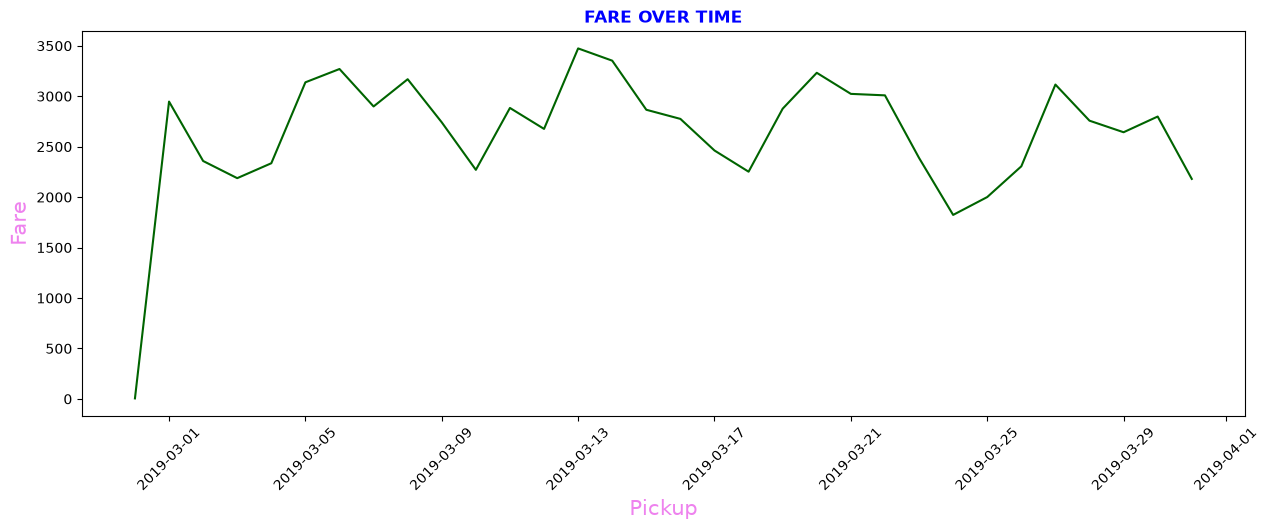

In [67]:
import matplotlib.pyplot as plt
plt.figure(figsize=(15,5))
df_daily=df.set_index('pickup')['fare'].resample('D').sum()
plt.plot(df_daily.index,df_daily.values,color='darkgreen')
plt.title('FARE OVER TIME',color='blue',fontweight='bold')
plt.xlabel('Pickup',color='violet',size=15)
plt.ylabel('Fare',color='violet',size=15)
plt.xticks(rotation=45)
plt.show()

### ★ Bar Chart
Create a bar chart to show the total fare for each pickup_borough. Group the data
by pickup_borough and sum the fare for each group.

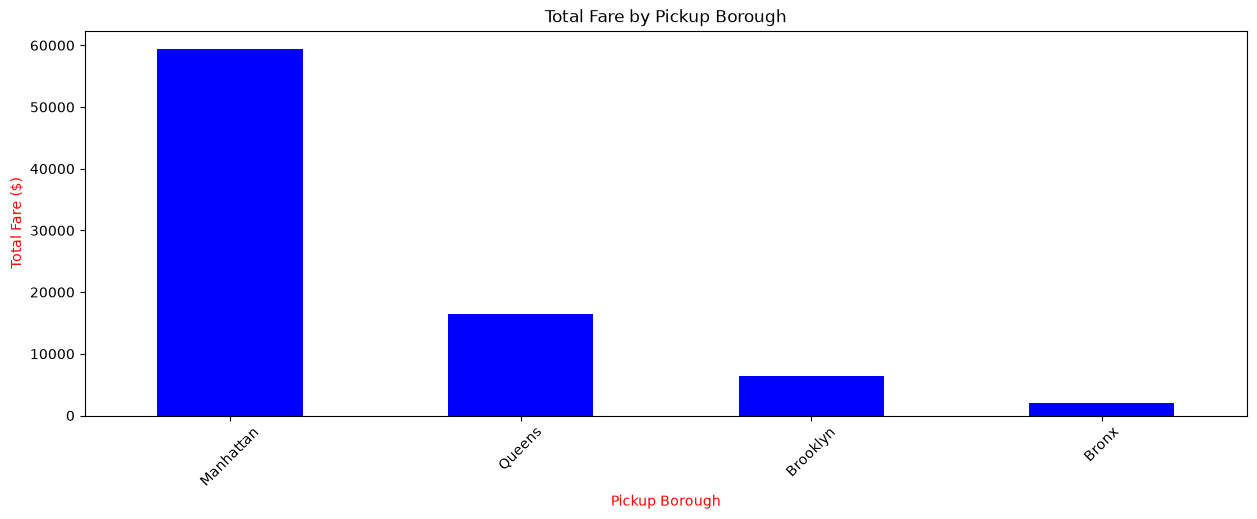

In [77]:
plt.figure(figsize=(15,5))
borough_fare=df.groupby('pickup_borough')['fare'].sum().sort_values(ascending=False)
borough_fare.plot(kind='bar',color='blue')
plt.title("Total Fare by Pickup Borough")
plt.xlabel("Pickup Borough",color='red')
plt.ylabel("Total Fare ($)",color='red')
plt.xticks(rotation=45)
plt.show()

### Manhattan Dominates Total Fare Revenue

### ★ Pie Chart
Plot a pie chart showing the distribution of trips based on the payment method (credit
card, cash, etc.). Each slice should represent the count of trips for a specific payment
method.

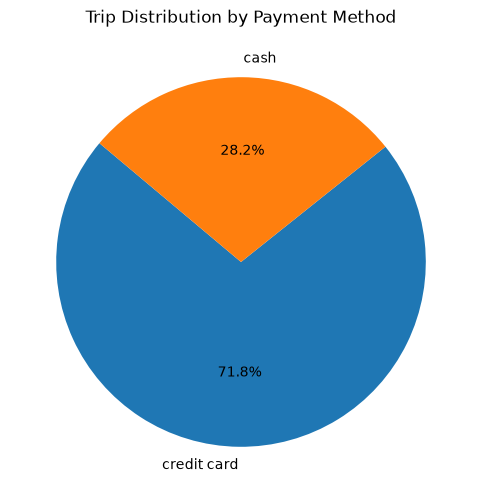

In [85]:
plt.figure(figsize=(8, 6))
payment_counts = df["payment"].value_counts()
plt.pie(
    payment_counts, labels=payment_counts.index, autopct="%1.1f%%", startangle=140
)
plt.title("Trip Distribution by Payment Method")
plt.show()

### credit card is the most used payment method

### ★ Histogram
Create a histogram to visualize the distribution of distance. Customize the number of
bins for better granularity and ensure the plot is easy to interpret.

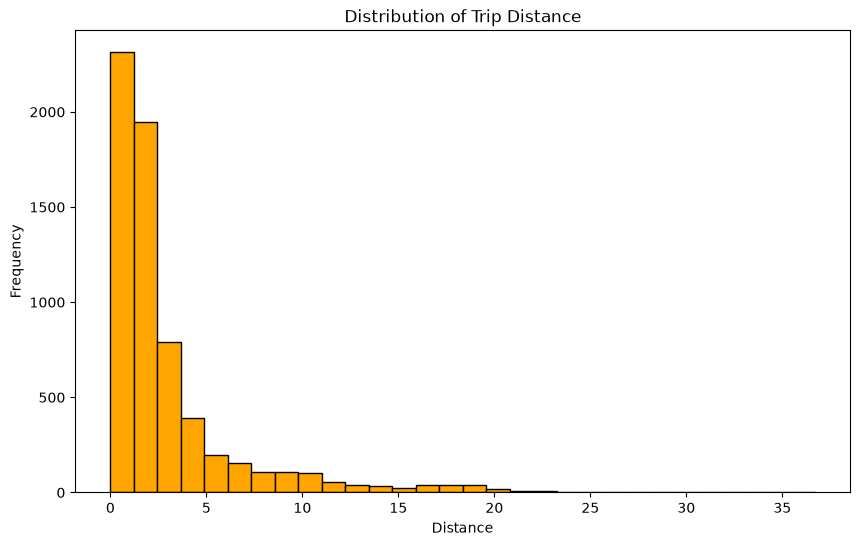

In [91]:
plt.figure(figsize=(10, 6))
plt.hist(df["distance"], bins=30, color="orange", edgecolor="black")
plt.title("Distribution of Trip Distance")
plt.xlabel("Distance")
plt.ylabel("Frequency")
plt.show()

### ★ Box Plot
Plot a box plot to visualize the distribution of tip amounts for each pickup_borough.
Use pickup_borough as the categorical axis and tip as the numeric axis.

<Figure size 1000x500 with 0 Axes>

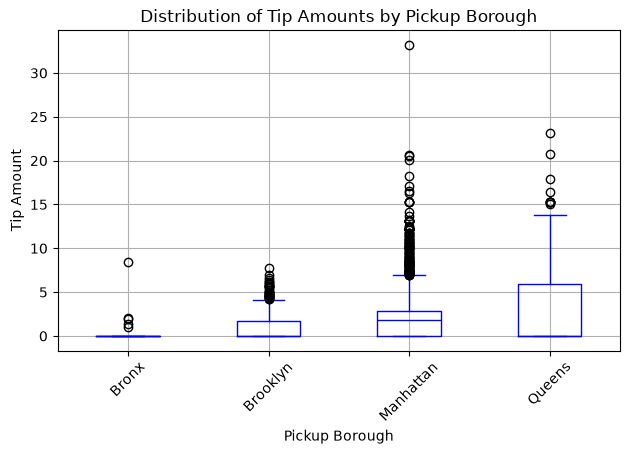

In [104]:
plt.figure(figsize=(10, 5))

df.boxplot(column='tip', by='pickup_borough',color='blue')

plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount')
plt.title('Distribution of Tip Amounts by Pickup Borough')
plt.suptitle('')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### ★ Count Plot
Create a count plot to visualize the number of trips in each pickup_borough. The
x-axis should represent the boroughs, and the y-axis should show the count of trips.

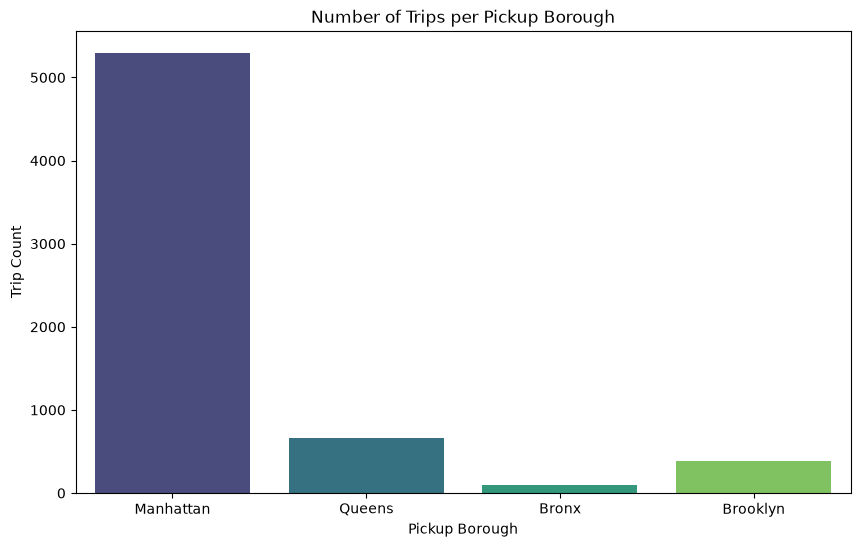

In [112]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df,x="pickup_borough",hue='pickup_borough', palette="viridis",legend=False)
plt.title("Number of Trips per Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Trip Count")
plt.show()

### ★ Scatter Plot
Plot a scatter plot to show the relationship between distance and fare. Use
distance on the x-axis and fare on the y-axis to visualize any correlation. Color the
points based on the pickup_borough to differentiate the trips by their respective
boroughs.

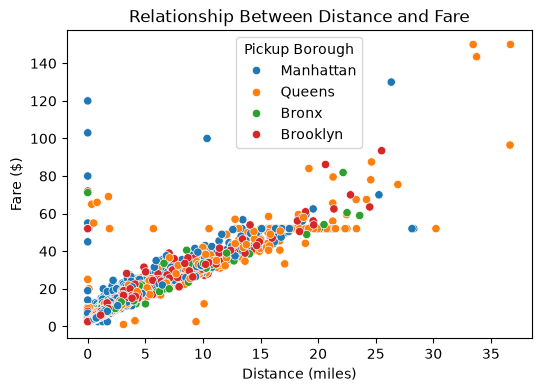

In [105]:
plt.figure(figsize=(6,4))
sns.scatterplot(data=df,x="distance",y="fare",hue="pickup_borough")
plt.title("Relationship Between Distance and Fare")
plt.xlabel("Distance (miles)")
plt.ylabel("Fare ($)")
plt.legend(title="Pickup Borough")
plt.show()

### ★ Heatmap
Plot a heatmap to visualize the correlation between numerical variables such as
distance, fare, tip, tolls, and total. Use a correlation matrix to highlight the
relationships.

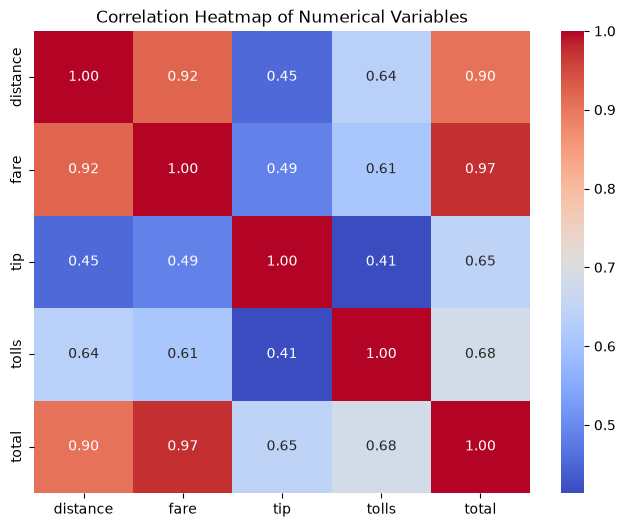

In [108]:
plt.figure(figsize=(8, 6))
numeric_df = df[["distance", "fare", "tip", "tolls", "total"]]
corr_matrix = numeric_df.corr()
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Numerical Variables")
plt.show()

### ★ Pair Plot
Create a pair plot to visualize the pairwise relationships between distance, fare, tip,
and total. Color the data points according to the pickup_zone method to compare
how different zones affect these variables.

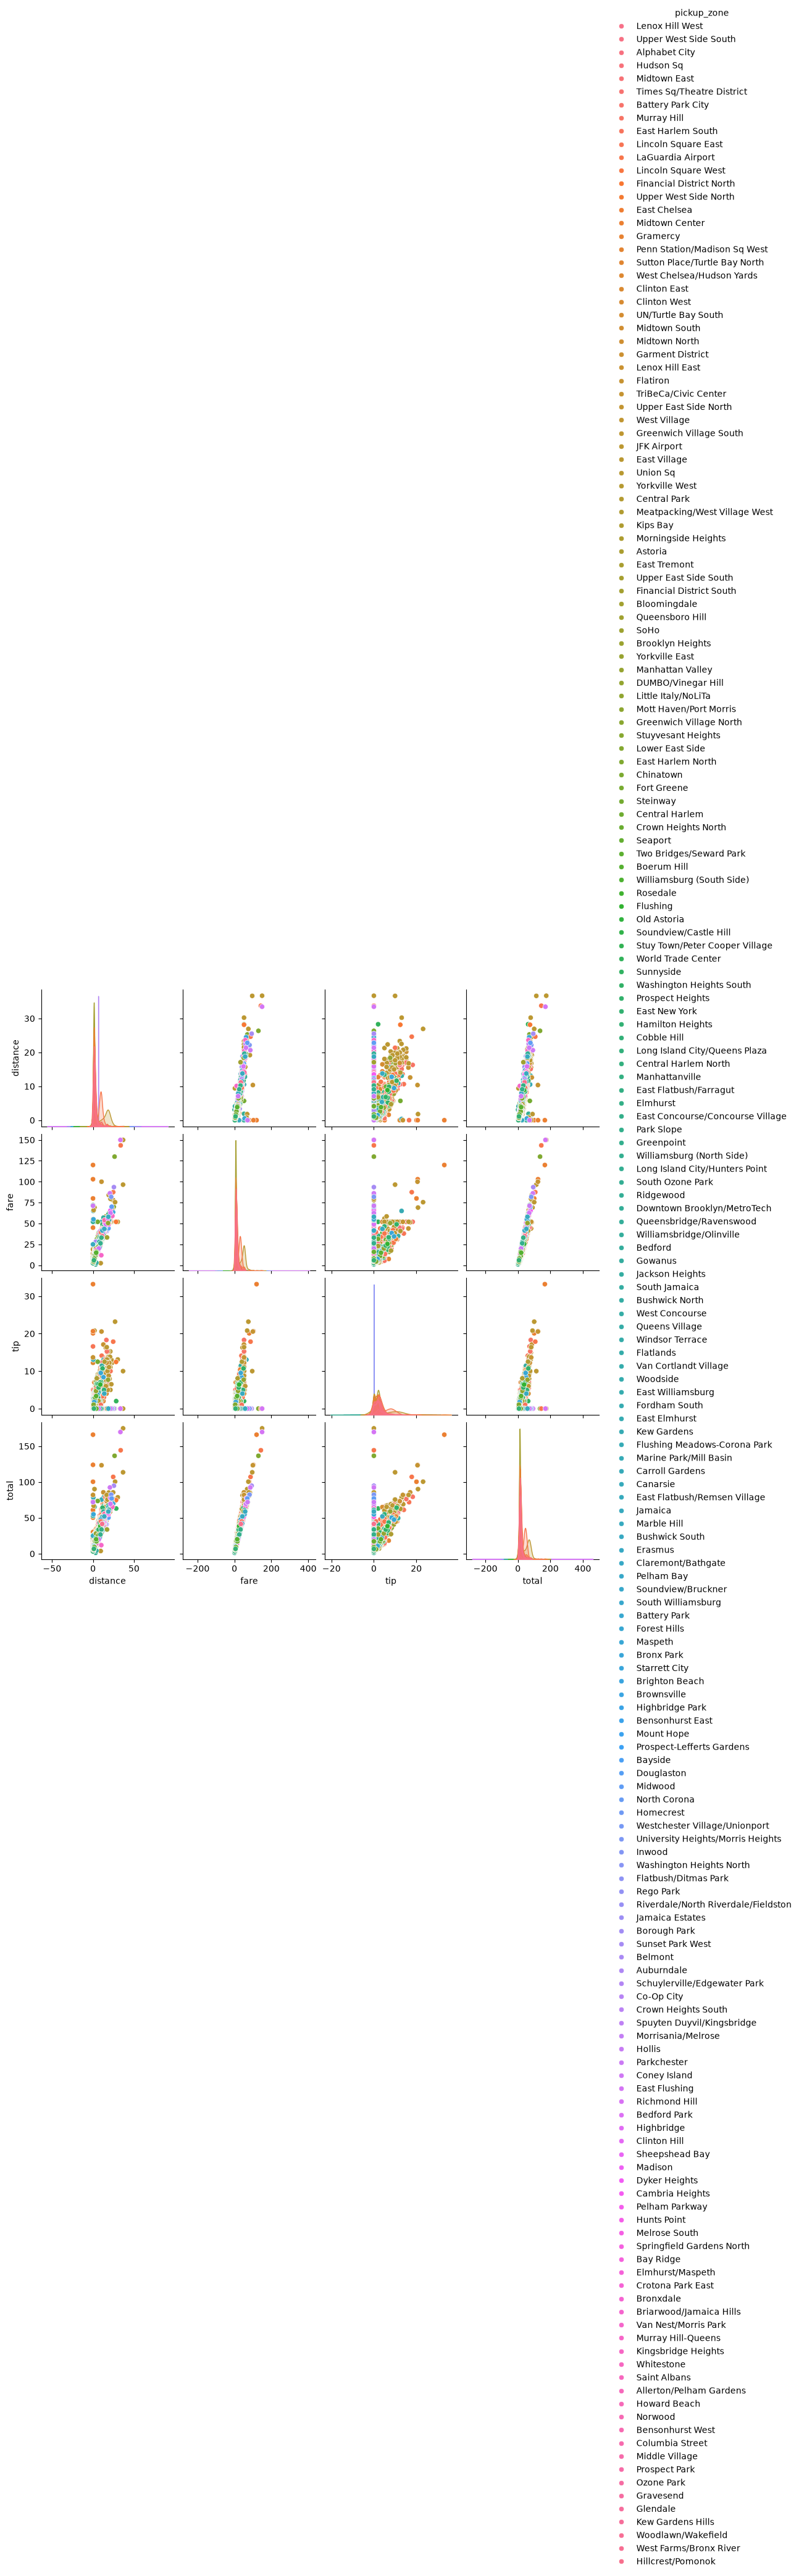

In [118]:
sns.pairplot(data=df,vars=["distance", "fare", "tip", "total"],hue="pickup_zone")
plt.show()

### ★ Violin Plot
Plot a violin plot to show the distribution of fare for each payment method. Use the payment method as the categorical axis and fare as the numeric axis to visualize its distribution.



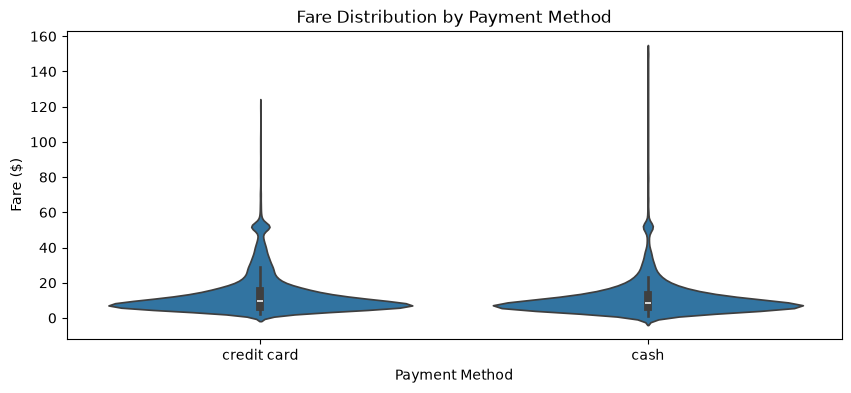

In [120]:
plt.figure(figsize=(10,4))
sns.violinplot(data=df,x="payment",y="fare")
plt.title("Fare Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Fare ($)")
plt.show()